# Validacion de la asignacion (v2): volumen modelado (Visum) vs aforo (IMEPLAN)

Segunda corrida, con los **volumenes de la asignacion ya reducidos**.

**Columnas:**

| Tipo | Columna | Significado |
|---|---|---|
| Visum (asignado) | `VOL_C_<per>` | Volumen asignado de **auto** |
| Visum (asignado) | `VOL_HF_<per>` | Volumen asignado de **carga pesada** |
| Visum (asignado) | `VOL_LF_<per>` | Volumen asignado de **carga ligera** |
| Aforo (real) | `CAR_COUNTS_<per>` | Aforo de **autos** |
| Aforo (real) | `FREIGHT_COUNTS_<per>` | Aforo de **carga** (pesada + ligera juntas) |
| Visum / Aforo | columnas con `TOTAL` | Volumen asignado total y aforo total |

**Dos analisis:**
- **A. Por modo y periodo:** Auto (`VOL_C` vs `CAR_COUNTS`) y Carga (`VOL_HF + VOL_LF` vs `FREIGHT_COUNTS`).
- **B. Totales por periodo:** `VOL ... TOTAL` vs `COUNTS ... TOTAL`.

En todos: solo links con aforo > 0 (0 = sin dato). Se calcula diferencia, error absoluto, % de error y **GEH**.

## 0. Carga de datos

In [37]:
import re
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#RUTA = "/Users/ebonyvaladez/Desktop/Septimo/on campus/271026/links_asignacion_271026_link.shp"   # <-- cambiar a la ruta del archivo nuevo
RUTA = "/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Validacion Asignacion/PrT/Link Volumes/271026"
PERIODOS = ["AP", "LM", "EA", "PP"]
#HORAS = {"AP": 5, "LM": 3, "EA": 6, "PP": 3}       # duracion de cada periodo (tabla de periodos)
#GEH_BASE = "GEH_periodo"                              # "GEH_hora" o "GEH_periodo"

gdf = gpd.read_file(RUTA)
print(gdf.shape)
print(gdf.columns.tolist())

(228854, 36)
['NO', 'FROMNODENO', 'TONODENO', 'TYPENO', 'NUMLANES', 'CAPPRT', 'V0PRT', 'CAR_COUN~1', 'VOL_C_AP', 'FREIGHT_~2', 'VOL_HF_AP', 'VOL_LF_AP', 'CAR_COUN~3', 'VOL_C_LM', 'FREIGHT_~4', 'VOL_HF_LM', 'VOL_LF_LM', 'CAR_COUN~5', 'VOL_C_EA', 'FREIGHT_~6', 'VOL_HF_EA', 'VOL_LF_EA', 'CAR_COUN~7', 'VOL_C_PP', 'FREIGHT_~8', 'VOL_HF_PP', 'VOL_LF_PP', 'TOTAL_CO~9', 'TOTAL_A~10', 'TOTAL_C~11', 'TOTAL_L~12', 'TOTAL_C~13', 'TOTAL_E~14', 'TOTAL_C~15', 'TOTAL_P~16', 'geometry']


## 1. Identificar las columnas
Se buscan por nombre. **Revisa la tabla que se imprime**: cada fila debe apuntar a la columna correcta.

Si alguna sale como `NO ENCONTRADA`, escribe el nombre real en `MANUAL`.

In [38]:
# Si algo no se encuentra, escribirlo aqui, por ejemplo:  MANUAL = {"aforo_total_AP": "COUNTS_TOT~1"}
MANUAL = {
    "aforo_auto_AP": "CAR_COUN~1", "aforo_carga_AP": "FREIGHT_~2",
    "aforo_auto_LM": "CAR_COUN~3", "aforo_carga_LM": "FREIGHT_~4",
    "aforo_auto_EA": "CAR_COUN~5", "aforo_carga_EA": "FREIGHT_~6",
    "aforo_auto_PP": "CAR_COUN~7", "aforo_carga_PP": "FREIGHT_~8",

    "aforo_total_AP": "TOTAL_CO~9",  "vol_total_AP": "TOTAL_V~10",
    "aforo_total_LM": "TOTAL_C~11",  "vol_total_LM": "TOTAL_V~12",
    "aforo_total_EA": "TOTAL_C~13",  "vol_total_EA": "TOTAL_V~14",
    "aforo_total_PP": "TOTAL_C~15",  "vol_total_PP": "TOTAL_V~16",
}

cols_up = {c.upper(): c for c in gdf.columns}

def exacta(nombre):
    return cols_up.get(nombre.upper())

def buscar_total(p, quiere_counts):
    """Columna que contiene TOTAL y el periodo; con COUNT (aforo) o sin COUNT (Visum)."""
    cands = [c for c in gdf.columns
             if "TOTAL" in c.upper()
             and re.search(rf"(^|_){p}($|_)", c.upper())
             and (("COUNT" in c.upper()) == quiere_counts)]
    return cands[0] if len(cands) == 1 else (cands if cands else None)

COL = {}
for p in PERIODOS:
    COL[f"vol_auto_{p}"]    = exacta(f"VOL_C_{p}")
    COL[f"vol_hf_{p}"]      = exacta(f"VOL_HF_{p}")
    COL[f"vol_lf_{p}"]      = exacta(f"VOL_LF_{p}")
    COL[f"aforo_auto_{p}"]  = exacta(f"CAR_COUNTS_{p}")
    COL[f"aforo_carga_{p}"] = exacta(f"FREIGHT_COUNTS_{p}")
    COL[f"vol_total_{p}"]   = buscar_total(p, quiere_counts=False)
    COL[f"aforo_total_{p}"] = buscar_total(p, quiere_counts=True)
COL.update(MANUAL)

revision = pd.DataFrame([
    {"variable": k,
     "columna_en_archivo": v if isinstance(v, str) else ("NO ENCONTRADA" if v is None else f"AMBIGUA: {v}")}
    for k, v in COL.items()])
print(revision.to_string(index=False))

faltan = revision[~revision["columna_en_archivo"].isin(gdf.columns)]
if len(faltan):
    print("\n>>> Revisar/llenar en MANUAL:", faltan["variable"].tolist())

      variable columna_en_archivo
   vol_auto_AP           VOL_C_AP
     vol_hf_AP          VOL_HF_AP
     vol_lf_AP          VOL_LF_AP
 aforo_auto_AP         CAR_COUN~1
aforo_carga_AP         FREIGHT_~2
  vol_total_AP         TOTAL_V~10
aforo_total_AP         TOTAL_CO~9
   vol_auto_LM           VOL_C_LM
     vol_hf_LM          VOL_HF_LM
     vol_lf_LM          VOL_LF_LM
 aforo_auto_LM         CAR_COUN~3
aforo_carga_LM         FREIGHT_~4
  vol_total_LM         TOTAL_V~12
aforo_total_LM         TOTAL_C~11
   vol_auto_EA           VOL_C_EA
     vol_hf_EA          VOL_HF_EA
     vol_lf_EA          VOL_LF_EA
 aforo_auto_EA         CAR_COUN~5
aforo_carga_EA         FREIGHT_~6
  vol_total_EA         TOTAL_V~14
aforo_total_EA         TOTAL_C~13
   vol_auto_PP           VOL_C_PP
     vol_hf_PP          VOL_HF_PP
     vol_lf_PP          VOL_LF_PP
 aforo_auto_PP         CAR_COUN~7
aforo_carga_PP         FREIGHT_~8
  vol_total_PP         TOTAL_V~16
aforo_total_PP         TOTAL_C~15

>>> Revisar/l

## 2. Construir variables limpias

In [59]:
def v(nombre):
    c = COL[nombre]
    return pd.to_numeric(gdf[c], errors="coerce").fillna(0) if isinstance(c, str) and c in gdf.columns else None

df = pd.DataFrame({"NO": gdf["NO"], "FROMNODENO": gdf["FROMNODENO"], "TONODENO": gdf["TONODENO"]})
if "TYPENO" in gdf.columns:
    df["TYPENO"] = gdf["TYPENO"]

for p in PERIODOS:
    for nombre in ["vol_auto", "vol_hf", "vol_lf", "aforo_auto", "aforo_carga", "vol_total", "aforo_total"]:
        serie = v(f"{nombre}_{p}")
        if serie is not None:
            df[f"{nombre}_{p}"] = serie
    if f"vol_hf_{p}" in df and f"vol_lf_{p}" in df:
        df[f"vol_carga_{p}"] = df[f"vol_hf_{p}"] + df[f"vol_lf_{p}"]     # carga modelada = HF + LF

# Filtro: links que permiten auto ("C" en TSYSSET), igual que en la primera version
"""if "TSYSSET" in gdf.columns:
    modos = gdf["TSYSSET"].fillna("").astype(str).str.split(",")
    df["PERMITE_AUTO"] = modos.apply(lambda s: "C" in [x.strip() for x in s])
else:
    df["PERMITE_AUTO"] = True
    print("No hay columna TSYSSET: se usan todos los links.")
"""

links = df.copy()

# Calcular volumen total modelado por periodo
for p in PERIODOS:

    links[f"vol_total_{p}"] = (
        links[f"vol_auto_{p}"]
        + links[f"vol_hf_{p}"]
        + links[f"vol_lf_{p}"]
    )
    
print(f"Total links: {len(df):,} | Links disponibles para comparar: {len(links):,}")

Total links: 228,854 | Links disponibles para comparar: 228,854


### Revision rapida: ¿el TOTAL es la suma de los modos?
Si el total de Visum = auto + HF + LF y el aforo total = aforo auto + aforo carga, la diferencia deberia ser ~0.

In [40]:
chequeo = []
for p in PERIODOS:
    fila = {"periodo": p}
    if all(f"{x}_{p}" in links for x in ["vol_total", "vol_auto", "vol_carga"]):
        d = links[f"vol_total_{p}"] - (links[f"vol_auto_{p}"] + links[f"vol_carga_{p}"])
        fila["vol_total = auto+HF+LF (% links)"] = round((d.abs() < 1).mean() * 100, 1)
    if all(f"{x}_{p}" in links for x in ["aforo_total", "aforo_auto", "aforo_carga"]):
        d = links[f"aforo_total_{p}"] - (links[f"aforo_auto_{p}"] + links[f"aforo_carga_{p}"])
        fila["aforo_total = auto+carga (% links)"] = round((d.abs() < 1).mean() * 100, 1)
    chequeo.append(fila)
pd.DataFrame(chequeo)

,periodo,aforo_total = auto+carga (% links)
0,AP,99.6
1,LM,99.6
2,EA,99.6
3,PP,99.6


## 3. Tabla resumen de links

In [41]:
tabla_resumen_links = pd.DataFrame({
    "total_links": len(df),
    "links_permiten_auto": len(links),
    "links_con_aforo_auto":  [(links[f"aforo_auto_{p}"] > 0).sum()  if f"aforo_auto_{p}" in links else np.nan for p in PERIODOS],
    "links_con_aforo_carga": [(links[f"aforo_carga_{p}"] > 0).sum() if f"aforo_carga_{p}" in links else np.nan for p in PERIODOS],
    "links_con_aforo_total": [(links[f"aforo_total_{p}"] > 0).sum() if f"aforo_total_{p}" in links else np.nan for p in PERIODOS],
}, index=pd.Index(PERIODOS, name="periodo"))
tabla_resumen_links

,total_links,links_permiten_auto,links_con_aforo_auto,links_con_aforo_carga,links_con_aforo_total
periodo,,,,,
AP,228854,228854,294,202,541
LM,228854,228854,294,249,540
EA,228854,228854,292,249,542
PP,228854,228854,293,180,541


In [42]:
for p in PERIODOS:
    con_total = links[f"aforo_total_{p}"] > 0
    con_desglose = (links[f"aforo_auto_{p}"] > 0) | (links[f"aforo_carga_{p}"] > 0)
    print(p, "| con desglose:", (con_total & con_desglose).sum(),
          "| solo total:", (con_total & ~con_desglose).sum())

AP | con desglose: 29 | solo total: 512
LM | con desglose: 29 | solo total: 511
EA | con desglose: 29 | solo total: 513
PP | con desglose: 29 | solo total: 512


In [43]:
for p in PERIODOS:
    ambas = links[(links[f"aforo_total_{p}"] > 0) &
                  ((links[f"aforo_auto_{p}"] > 0) | (links[f"aforo_carga_{p}"] > 0))]
    suma = ambas[f"aforo_auto_{p}"] + ambas[f"aforo_carga_{p}"]
    cuadra = ((ambas[f"aforo_total_{p}"] - suma).abs() < 1).mean() * 100
    print(p, "| calles:", len(ambas), "| total = auto+carga en", round(cuadra, 1), "%")

AP | calles: 29 | total = auto+carga en 0.0 %
LM | calles: 29 | total = auto+carga en 3.4 %
EA | calles: 29 | total = auto+carga en 0.0 %
PP | calles: 29 | total = auto+carga en 0.0 %


## 4. Funciones: tabla por link, GEH y resumen

$GEH = \\sqrt{\\dfrac{2(M-C)^2}{M+C}}$, con **M = modelado (Visum)** y **C = aforo**.
GEH < 5 bien | 5-10 regular | > 10 mal. Meta usual: 85 % de links con GEH < 5.

- `GEH_periodo`: con el volumen del periodo tal cual.
- `GEH_hora`: dividiendo entre las horas del periodo (los umbrales 5 y 10 estan pensados por hora).

In [44]:
def geh(m, c):
    return np.sqrt(2 * (m - c) ** 2 / (m + c))

def tabla_por_link(base, aforo, modelado, modo, extra=()):
    partes = []
    for p in PERIODOS:
        if f"{aforo}_{p}" not in base or f"{modelado}_{p}" not in base:
            continue
        #sub = base[base[f"{aforo}_{p}"] > 0]
        sub = base[(base[f"{aforo}_{p}"] > 0) & (base[f"{modelado}_{p}"] >= 0)].copy()
        t = sub[[c for c in ["NO", "FROMNODENO", "TONODENO", "TYPENO"] if c in sub]].copy()
        t["modo"] = modo
        t["periodo"] = p
        t["vol_observado"] = sub[f"{aforo}_{p}"]
        for e in extra:
            if f"{e}_{p}" in sub:
                t[e] = sub[f"{e}_{p}"]
        t["vol_modelado"] = sub[f"{modelado}_{p}"]
        t["diferencia"] = t["vol_modelado"] - t["vol_observado"]
        t["error_absoluto"] = t["diferencia"].abs()
        t["pct_error"] = t["diferencia"] / t["vol_observado"] * 100
        t["GEH"] = geh(t["vol_modelado"], t["vol_observado"])
        t["rango_GEH"] = pd.cut(t["GEH"], [-np.inf, 5, 10, np.inf], right=False,
                                labels=["< 5", "5 - 10", ">= 10"])
        partes.append(t)
    return pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()


def resumir(t):
    g = t.groupby(["modo", "periodo"], sort=False)
    r = pd.DataFrame({
        "links_con_aforo": g.size(),
        "vol_observado_total": g["vol_observado"].sum(),
        "vol_modelado_total": g["vol_modelado"].sum(),
        "GEH_promedio": g["GEH"].mean(),
        "GEH_mediana": g["GEH"].median(),
        "n_GEH<5":    g["GEH"].apply(lambda x: (x < 5).sum()),
        "n_GEH_5a10": g["GEH"].apply(lambda x: ((x >= 5) & (x < 10)).sum()),
        "n_GEH>10":   g["GEH"].apply(lambda x: (x >= 10).sum()),
        "sesgo_promedio": g["diferencia"].mean(),
        "pct_error_mediana": g["pct_error"].median(),
    })

    r["dif_total_%"] = (r["vol_modelado_total"] - r["vol_observado_total"]) / r["vol_observado_total"] * 100
    for col in ["n_GEH<5", "n_GEH_5a10", "n_GEH>10"]:
        r["%" + col[1:]] = r[col] / r["links_con_aforo"] * 100
    r["cumple_85%"] = r["%_GEH<5"] >= 85
    r["R2"] = g.apply(lambda x: np.corrcoef(x["vol_modelado"], x["vol_observado"])[0, 1] ** 2
                      if len(x) > 1 else np.nan)
    return r.round(2)

## A. Analisis por modo y periodo
- **Auto:** `VOL_C` vs `CAR_COUNTS`
- **Carga:** `VOL_HF + VOL_LF` vs `FREIGHT_COUNTS`

In [45]:
tabla_auto  = tabla_por_link(links, "aforo_auto",  "vol_auto",  "AUTO")
tabla_carga = tabla_por_link(links, "aforo_carga", "vol_carga", "FREIGHT", extra=("vol_hf", "vol_lf"))
tabla_auto.head(15)

,NO,FROMNODENO,TONODENO,TYPENO,modo,periodo,vol_observado,vol_modelado,diferencia,error_absoluto,pct_error,GEH,rango_GEH
0,95755,37902,44413,303,AUTO,AP,7,390,383,383,5471.428571,27.184323,>= 10
1,95757,37903,37902,302,AUTO,AP,6,850,844,844,14066.666667,40.796280,>= 10
2,96016,38015,76091,501,AUTO,AP,7,0,-7,7,-100.000000,3.741657,< 5
3,96016,76091,38015,502,AUTO,AP,475,203,-272,272,-57.263158,14.773012,>= 10
4,96017,38015,44453,402,AUTO,AP,296,300,4,4,1.351351,0.231714,< 5
5,97144,38527,38667,501,AUTO,AP,79,175,96,96,121.518987,8.518622,5 - 10
6,97145,38527,38538,501,AUTO,AP,34,0,-34,34,-100.000000,8.246211,5 - 10
7,97279,38584,38527,502,AUTO,AP,63,0,-63,63,-100.000000,11.224972,>= 10
8,97348,38612,38527,502,AUTO,AP,146,175,29,29,19.863014,2.289077,< 5
9,97440,38654,38686,303,AUTO,AP,59,2870,2811,2811,4764.406780,73.454120,>= 10


In [46]:
tabla_carga.head(15)

,NO,FROMNODENO,TONODENO,TYPENO,modo,periodo,vol_observado,vol_hf,vol_lf,vol_modelado,diferencia,error_absoluto,pct_error,GEH,rango_GEH
0,96016,38015,76091,501,FREIGHT,AP,4,0,0,0,-4,4,-100.000000,2.828427,< 5
1,96016,76091,38015,502,FREIGHT,AP,15,0,0,0,-15,15,-100.000000,5.477226,5 - 10
2,97145,38527,38538,501,FREIGHT,AP,1,0,0,0,-1,1,-100.000000,1.414214,< 5
3,97279,38584,38527,502,FREIGHT,AP,2,0,0,0,-2,2,-100.000000,2.000000,< 5
4,97348,38612,38527,502,FREIGHT,AP,2,0,0,0,-2,2,-100.000000,2.000000,< 5
5,97655,38757,104530,501,FREIGHT,AP,1,0,0,0,-1,1,-100.000000,1.414214,< 5
6,97656,38757,202300,514,FREIGHT,AP,10,0,0,0,-10,10,-100.000000,4.472136,< 5
7,97677,38767,38781,402,FREIGHT,AP,1,0,0,0,-1,1,-100.000000,1.414214,< 5
8,97692,38781,38774,502,FREIGHT,AP,1,0,0,0,-1,1,-100.000000,1.414214,< 5
9,97783,38809,38781,502,FREIGHT,AP,1,0,0,0,-1,1,-100.000000,1.414214,< 5


In [47]:
resumen_modo = resumir(pd.concat([tabla_auto, tabla_carga]))
resumen_modo

links_con_aforo  vol_observado_total  vol_modelado_total  \
modo    periodo                                                             
AUTO    AP                   294               147109              142286   
        LM                   294               159923               69369   
        EA                   292               187655              124208   
        PP                   293               205779              120536   
FREIGHT AP                   202                 1116                 613   
        LM                   249                 1992                1352   
        EA                   249                 1980                1018   
        PP                   180                  978                 485   

                 GEH_promedio  GEH_mediana  n_GEH<5  n_GEH_5a10  n_GEH>10  \
modo    periodo                                                             
AUTO    AP              16.99        13.97       49          51       194   
        LM              19.20        16.52       39          44       211   
        EA              18.24        15.97       46          54       192   
        PP              19.95        16.46       33          59       201   
FREIGHT AP               2.86         2.45      177          22         3   
        LM               3.34         2.67      211          34         4   
        EA               3.19         2.45      208          38         3   
        PP               2.71         2.57      167          11         2   

                 sesgo_promedio  pct_error_mediana  dif_total_%  %_GEH<5  \
modo    periodo                                                            
AUTO    AP               -16.40             -35.45        -3.28    16.67   
        LM              -308.01             -76.64       -56.62    13.27   
        EA              -217.28             -51.81       -33.81    15.75   
        PP              -290.93             -63.81       -41.42    11.26   
FREIGHT AP                -2.49            -100.00       -45.07    87.62   
        LM                -2.57            -100.00       -32.13    84.74   
        EA                -3.86            -100.00       -48.59    83.53   
        PP                -2.74            -100.00       -50.41    92.78   

                 %_GEH_5a10  %_GEH>10  cumple_85%    R2  
modo    periodo                                          
AUTO    AP            17.35     65.99       False  0.30  
        LM            14.97     71.77       False  0.30  
        EA            18.49     65.75       False  0.34  
        PP            20.14     68.60       False  0.32  
FREIGHT AP            10.89      1.49        True  0.05  
        LM            13.65      1.61       False  0.06  
        EA            15.26      1.20       False  0.06  
        PP             6.11      1.11        True  0.19

## B. Analisis de TOTALES por periodo
`VOL ... TOTAL` (Visum) vs `COUNTS ... TOTAL` (aforo), solo donde el aforo total > 0.

In [60]:
"""tabla_total = tabla_por_link(links, "aforo_total", "vol_total", "Total")
resumen_total = resumir(tabla_total) if len(tabla_total) else pd.DataFrame()
resumen_total"""

tabla_total = tabla_por_link(
    links,
    "aforo_total",
    "vol_total",
    "TOTAL"
)

resumen_total = (
    resumir(tabla_total)
    if len(tabla_total)
    else pd.DataFrame()
)

display(resumen_total)

links_con_aforo  vol_observado_total  vol_modelado_total  \
modo  periodo                                                             
TOTAL AP                   541            779096.58              640658   
      LM                   540            682721.38              302553   
      EA                   542            815051.35              543703   
      PP                   541            899198.00              539440   

               GEH_promedio  GEH_mediana  n_GEH<5  n_GEH_5a10  n_GEH>10  \
modo  periodo                                                             
TOTAL AP              23.73        18.44       76          76       389   
      LM              26.98        24.57       49          47       444   
      EA              23.66        19.54       68          81       393   
      PP              26.77        23.38       52          58       431   

               sesgo_promedio  pct_error_mediana  dif_total_%  %_GEH<5  \
modo  periodo                                                            
TOTAL AP              -255.89             -20.88       -17.77    14.05   
      LM              -704.02             -61.36       -55.68     9.07   
      EA              -500.64             -36.95       -33.29    12.55   
      PP              -664.99             -46.11       -40.01     9.61   

               %_GEH_5a10  %_GEH>10  cumple_85%    R2  
modo  periodo                                          
TOTAL AP            14.05     71.90       False  0.07  
      LM             8.70     82.22       False  0.05  
      EA            14.94     72.51       False  0.10  
      PP            10.72     79.67       False  0.11

## 5. Estadisticas basicas
Promedio, mediana, minimo, maximo y percentiles. La **mediana** es mas confiable que el promedio cuando hay calles con errores enormes.

In [49]:
todo = pd.concat([tabla_auto, tabla_carga, tabla_total], ignore_index=True)
resumen_completo = resumir(todo)
display(resumen_completo)

cols_stats = ["vol_observado", "vol_modelado", "diferencia", "pct_error", "GEH"]
stats_basicas = (todo.groupby(["modo", "periodo"], sort=False)[cols_stats]
                 .describe(percentiles=[.25, .5, .75])
                 .stack(level=0, future_stack=True)
                 .rename_axis(["modo", "periodo", "variable"])
                 .rename(columns={"count": "n", "mean": "promedio", "std": "desv_std", "min": "minimo",
                                  "25%": "p25", "50%": "mediana", "75%": "p75", "max": "maximo"})
                 .round(2))
stats_basicas


links_con_aforo  vol_observado_total  vol_modelado_total  \
modo    periodo                                                             
AUTO    AP                   294               147109              142286   
        LM                   294               159923               69369   
        EA                   292               187655              124208   
        PP                   293               205779              120536   
FREIGHT AP                   202                 1116                 613   
        LM                   249                 1992                1352   
        EA                   249                 1980                1018   
        PP                   180                  978                 485   

                 GEH_promedio  GEH_mediana  n_GEH<5  n_GEH_5a10  n_GEH>10  \
modo    periodo                                                             
AUTO    AP              16.99        13.97       49          51       194   
        LM              19.20        16.52       39          44       211   
        EA              18.24        15.97       46          54       192   
        PP              19.95        16.46       33          59       201   
FREIGHT AP               2.86         2.45      177          22         3   
        LM               3.34         2.67      211          34         4   
        EA               3.19         2.45      208          38         3   
        PP               2.71         2.57      167          11         2   

                 sesgo_promedio  pct_error_mediana  dif_total_%  %_GEH<5  \
modo    periodo                                                            
AUTO    AP               -16.40             -35.45        -3.28    16.67   
        LM              -308.01             -76.64       -56.62    13.27   
        EA              -217.28             -51.81       -33.81    15.75   
        PP              -290.93             -63.81       -41.42    11.26   
FREIGHT AP                -2.49            -100.00       -45.07    87.62   
        LM                -2.57            -100.00       -32.13    84.74   
        EA                -3.86            -100.00       -48.59    83.53   
        PP                -2.74            -100.00       -50.41    92.78   

                 %_GEH_5a10  %_GEH>10  cumple_85%    R2  
modo    periodo                                          
AUTO    AP            17.35     65.99       False  0.30  
        LM            14.97     71.77       False  0.30  
        EA            18.49     65.75       False  0.34  
        PP            20.14     68.60       False  0.32  
FREIGHT AP            10.89      1.49        True  0.05  
        LM            13.65      1.61       False  0.06  
        EA            15.26      1.20       False  0.06  
        PP             6.11      1.11        True  0.19

n  promedio  desv_std   minimo     p25  \
modo    periodo variable                                                    
AUTO    AP      vol_observado  294.0    500.37    640.93     1.00   71.00   
                vol_modelado   294.0    483.97    673.57     0.00    3.00   
                diferencia     294.0    -16.40    622.87 -2597.00 -250.25   
                pct_error      294.0    528.71   3071.86  -100.00  -97.54   
                GEH            294.0     16.99     13.38     0.23    7.65   
        LM      vol_observado  294.0    543.96    650.87     1.00   81.25   
                vol_modelado   294.0    235.95    352.44     0.00    0.00   
                diferencia     294.0   -308.01    543.72 -2600.00 -542.25   
                pct_error      294.0    244.47   2409.59  -100.00 -100.00   
                GEH            294.0     19.20     13.67     0.00    8.79   
        EA      vol_observado  292.0    642.65    745.32     1.00   99.00   
                vol_modelado   292.0    425.37    595.40     0.00   28.50   
                diferencia     292.0   -217.28    625.74 -2672.00 -485.50   
                pct_error      292.0    580.15   5629.97  -100.00  -90.64   
                GEH            292.0     18.24     13.56     0.12    7.71   
        PP      vol_observado  293.0    702.32    816.04     1.00  103.00   
                vol_modelado   293.0    411.39    588.76     0.00    0.00   
                diferencia     293.0   -290.93    685.66 -3055.00 -601.00   
                pct_error      293.0    529.32   4121.66  -100.00 -100.00   
                GEH            293.0     19.95     14.63     0.00    8.23   
FREIGHT AP      vol_observado  202.0      5.52      5.89     1.00    1.00   
                vol_modelado   202.0      3.03     17.49     0.00    0.00   
                diferencia     202.0     -2.49     17.21   -27.00   -7.00   
                pct_error      202.0    -15.57    694.85  -100.00 -100.00   
                GEH            202.0      2.86      2.17     0.00    1.41   
        LM      vol_observado  249.0      8.00      9.53     1.00    2.00   
                vol_modelado   249.0      5.43     31.52     0.00    0.00   
                diferencia     249.0     -2.57     30.52   -45.00   -9.00   
                pct_error      249.0     22.90    873.44  -100.00 -100.00   
                GEH            249.0      3.34      2.79     0.00    1.60   
        EA      vol_observado  249.0      7.95      9.49     1.00    2.00   
                vol_modelado   249.0      4.09     21.18     0.00    0.00   
                diferencia     249.0     -3.86     20.89   -41.00   -9.00   
                pct_error      249.0     25.26    945.67  -100.00 -100.00   
                GEH            249.0      3.19      2.45     0.00    1.41   
        PP      vol_observado  180.0      5.43      6.49     1.00    2.00   
                vol_modelado   180.0      2.69     13.39     0.00    0.00   
                diferencia     180.0     -2.74     12.11   -23.00   -6.00   
                pct_error      180.0    -30.58    429.85  -100.00 -100.00   
                GEH            180.0      2.71      1.78     0.00    1.41   

                               mediana      p75    maximo  
modo    periodo variable                                   
AUTO    AP      vol_observado   234.50   684.00   3620.00  
                vol_modelado    196.00   736.00   4011.00  
                diferencia      -42.50   148.00   2882.00  
                pct_error       -35.45    70.50  38500.00  
                GEH              13.97    23.87     73.45  
        LM      vol_observado   277.00   756.25   3268.00  
                vol_modelado    115.00   292.25   2245.00  
                diferencia     -136.50   -25.00   1248.00  
                pct_error       -76.64   -28.80  37200.00  
                GEH              16.52    26.81     66.67  
        EA      vol_observado   316.50   917.75   4083.00  
                vol_

## 6. Error segun el nivel de trafico observado
Se agrupan las calles por **cuantos vehiculos se contaron**. Permite ver si el modelo falla igual en calles con poco y con mucho trafico.

In [20]:
CORTES = [0, 100, 250, 500, 1000, np.inf]
ETIQ = ["1-100", "101-250", "251-500", "501-1000", "> 1000"]
todo["nivel_trafico"] = pd.cut(todo["vol_observado"], CORTES, labels=ETIQ)

def resumen_grupo(t, col):
    g = t.groupby(["modo", col], observed=True, sort=False)
    return pd.DataFrame({
        "n_calles": g.size(),
        "vol_observado_prom": g["vol_observado"].mean(),
        "vol_modelado_prom": g["vol_modelado"].mean(),
        "sesgo_promedio": g["diferencia"].mean(),
        "pct_error_mediana": g["pct_error"].median(),
        "GEH_promedio": g["GEH"].mean(),
        "%_GEH<5":  g["GEH"].apply(lambda x: (x < 5).mean() * 100),
        "%_GEH>10": g["GEH"].apply(lambda x: (x >= 10).mean() * 100),
    }).round(2).reset_index()

error_nivel = resumen_grupo(todo, "nivel_trafico")
error_nivel["nivel_trafico"] = pd.Categorical(error_nivel["nivel_trafico"], categories=ETIQ, ordered=True)
error_nivel = error_nivel.sort_values(["modo", "nivel_trafico"]).reset_index(drop=True)

error_nivel

,modo,nivel_trafico,n_calles,vol_observado_prom,vol_modelado_prom,sesgo_promedio,pct_error_mediana,GEH_promedio,%_GEH<5,%_GEH>10
0,Auto,1-100,326,45.06,174.87,129.82,-47.38,12.97,19.33,50.31
1,Auto,101-250,222,159.48,155.36,-4.11,-76.51,13.82,17.12,67.12
2,Auto,251-500,163,353.68,312.84,-40.84,-64.27,19.22,9.82,77.91
3,Auto,501-1000,213,727.64,394.41,-333.23,-61.91,20.80,14.08,71.36
4,Auto,> 1000,249,1757.98,923.28,-834.69,-53.74,27.92,8.03,82.73
5,Carga (HF+LF),1-100,880,6.89,3.94,-2.95,-100.00,3.06,86.70,1.36


## 7. Error segun el tipo de calle (`TYPENO`)

In [21]:
error_tipo = (resumen_grupo(todo, "TYPENO").sort_values(["modo", "n_calles"], ascending=[True, False])
              if "TYPENO" in todo else pd.DataFrame())
error_tipo

,modo,TYPENO,n_calles,vol_observado_prom,vol_modelado_prom,sesgo_promedio,pct_error_mediana,GEH_promedio,%_GEH<5,%_GEH>10
3,Auto,502,272,198.39,59.83,-138.56,-100.00,13.93,14.71,60.29
2,Auto,501,247,214.71,93.97,-120.74,-91.85,13.87,20.24,58.70
4,Auto,402,242,735.23,318.21,-417.02,-62.66,23.09,10.74,74.38
1,Auto,302,148,935.34,713.57,-221.78,-30.14,21.48,9.46,79.73
10,Auto,202,60,1043.78,756.43,-287.35,-36.06,16.89,21.67,66.67
0,Auto,303,44,762.84,683.16,-79.68,-47.32,28.26,4.55,84.09
9,Auto,304,44,885.77,894.11,8.34,-12.29,21.22,18.18,59.09
7,Auto,403,36,866.11,416.83,-449.28,-60.86,24.65,8.33,83.33
11,Auto,203,32,1351.81,1078.62,-273.19,-39.46,18.48,6.25,78.12
6,Auto,103,16,1892.62,2868.12,975.50,30.78,27.24,12.50,68.75


## 8. Graficas
**Puntos observado vs modelado:** cada punto es una calle. Arriba de la linea = Visum puso de mas; abajo = de menos. Color = rango GEH.

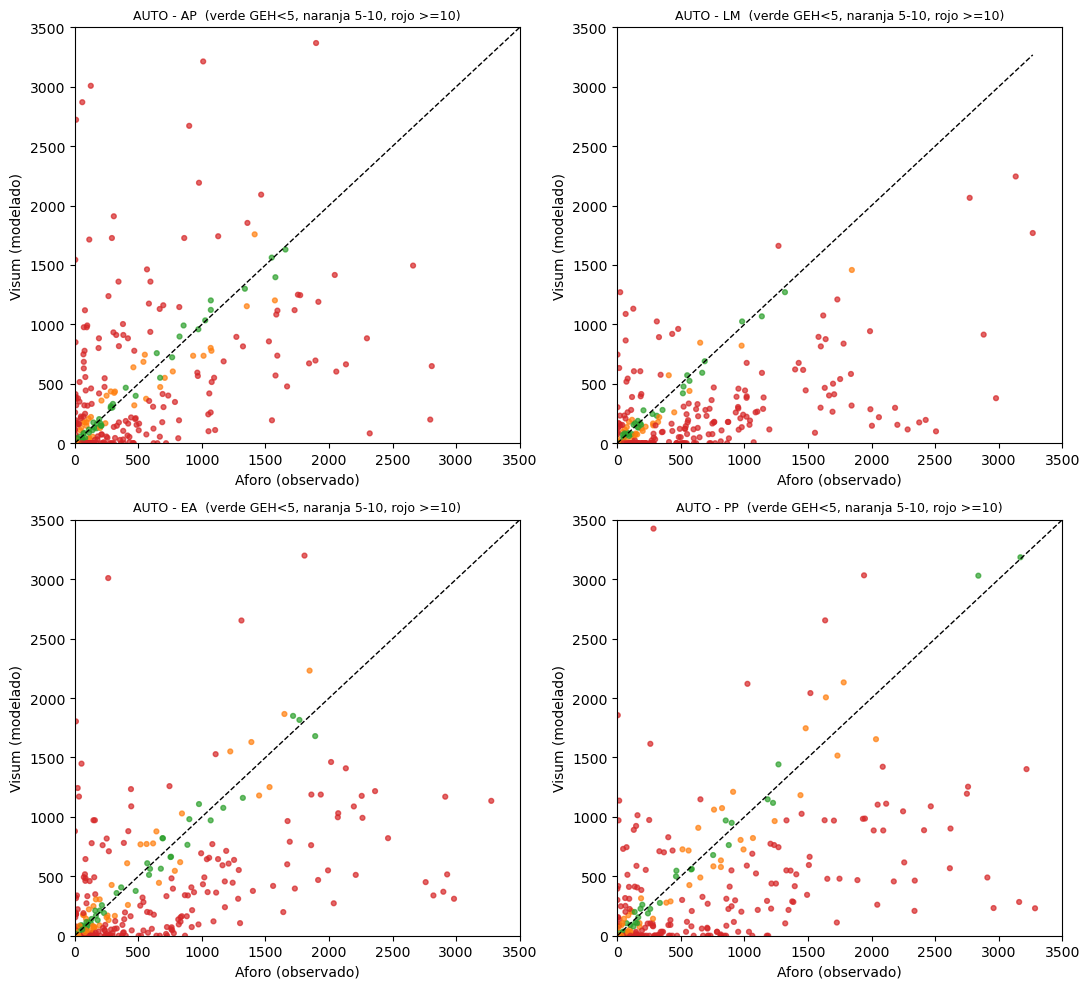

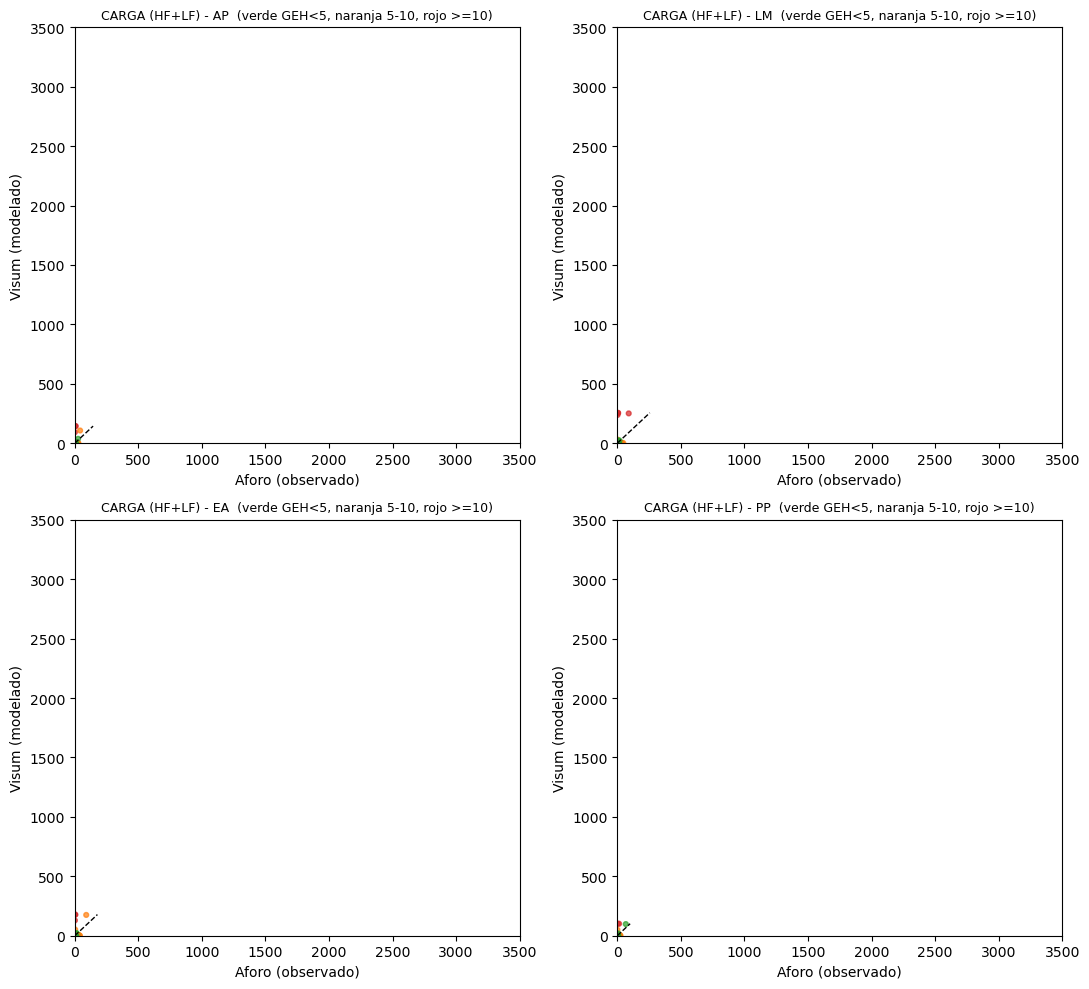

In [54]:
COLORES_GEH = {"< 5": "tab:green", "5 - 10": "tab:orange", ">= 10": "tab:red"}

def dispersion(t, titulo):
    if t.empty: return
    fig, axes = plt.subplots(2, 2, figsize=(11, 10))
    for ax, p in zip(axes.flat, PERIODOS):
        d = t[t["periodo"] == p]
        if d.empty: ax.set_visible(False); continue
        ax.scatter(d["vol_observado"], d["vol_modelado"], c=d["rango_GEH"].map(COLORES_GEH), s=12, alpha=0.7)
        lim = max(d["vol_observado"].max(), d["vol_modelado"].max())
        ax.plot([0, lim], [0, lim], "k--", lw=1)
        ax.set_xlim(0, 3500); ax.set_ylim(0, 3500)
        ax.set_title(f"{titulo} - {p}  (verde GEH<5, naranja 5-10, rojo >=10)", fontsize=9)
        ax.set_xlabel("Aforo (observado)"); ax.set_ylabel("Visum (modelado)")
    plt.tight_layout(); plt.show()

dispersion(tabla_auto, "AUTO")
dispersion(tabla_carga, "CARGA (HF+LF)")
dispersion(tabla_total, "TOTAL")

**% de links por rango de GEH** (la linea punteada es la meta de 85 %):

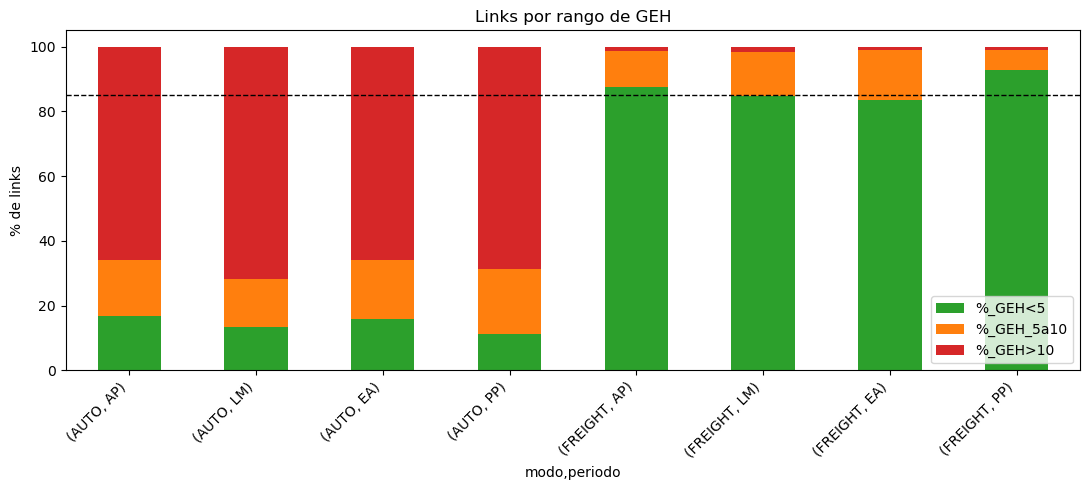

In [55]:
res_todo = pd.concat([resumen_modo, resumen_total])
pct = res_todo[["%_GEH<5", "%_GEH_5a10", "%_GEH>10"]]
ax = pct.plot(kind="bar", stacked=True, figsize=(11, 5), color=["tab:green", "tab:orange", "tab:red"])
ax.axhline(85, color="k", ls="--", lw=1)
ax.set_ylabel("% de links"); ax.set_title("Links por rango de GEH")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()


**Sesgo por nivel de trafico** (rojo = Visum pone de mas, azul = pone de menos):

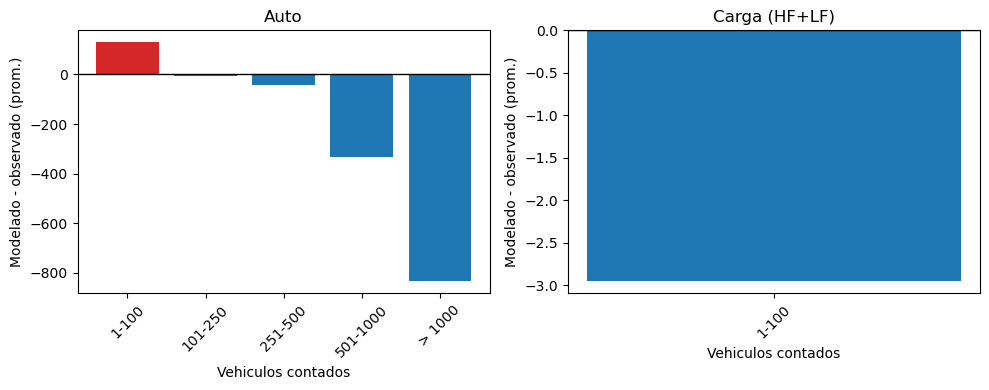

In [24]:
modos = error_nivel["modo"].unique()
fig, axes = plt.subplots(1, len(modos), figsize=(5 * len(modos), 4), squeeze=False)
for ax, m in zip(axes[0], modos):
    d = error_nivel[error_nivel["modo"] == m]
    ax.bar(d["nivel_trafico"].astype(str), d["sesgo_promedio"],
           color=["tab:red" if x > 0 else "tab:blue" for x in d["sesgo_promedio"]])
    ax.axhline(0, color="k", lw=1)
    ax.set_title(m); ax.set_xlabel("Vehiculos contados"); ax.set_ylabel("Modelado - observado (prom.)")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 9. Comparacion contra la primera version
Si tienes el Excel de la corrida anterior (`comparacion_volumenes.xlsx`), esta celda compara el % de links con GEH < 5 antes y ahora.

In [ ]:
RUTA_ANTERIOR = "/Users/ebonyvaladez/Desktop/Septimo/on campus/comparacion_volumenes.xlsx"   # Excel de la primera version
try:
    ant = pd.read_excel(RUTA_ANTERIOR, sheet_name="4_resumen_por_modo")
    ant["modo"] = ant["modo"].replace({"Carga (HF+LF)": "Carga (HF+LF)", "Carga": "Carga (HF+LF)"})
    ant = ant.set_index(["modo", "periodo"])[["vol_observado_total", "vol_modelado_total", "GEH_mediana", "%_GEH<5"]]
    nuevo = resumen_modo[["vol_observado_total", "vol_modelado_total", "GEH_mediana", "%_GEH<5"]]
    comparacion_versiones = ant.join(nuevo, lsuffix="_v1", rsuffix="_v2")
    comparacion_versiones["cambio_%_GEH<5"] = comparacion_versiones["%_GEH<5_v2"] - comparacion_versiones["%_GEH<5_v1"]
    display(comparacion_versiones.round(2))
except FileNotFoundError:
    comparacion_versiones = pd.DataFrame()
    print("No se encontro el Excel anterior; se omite la comparacion.")

No se encontro el Excel anterior; se omite la comparacion.


## 10. Exportar

In [21]:
with pd.ExcelWriter("/Users/ebonyvaladez/Desktop/Septimo/on campus/comparacion_volumenes_v2.xlsx") as xw:
    revision.to_excel(xw, sheet_name="0_columnas_usadas", index=False)
    tabla_resumen_links.to_excel(xw, sheet_name="1_resumen_links")
    tabla_auto.to_excel(xw, sheet_name="2_auto_por_link", index=False)
    tabla_carga.to_excel(xw, sheet_name="3_carga_por_link", index=False)
    resumen_modo.to_excel(xw, sheet_name="4_resumen_por_modo")
    tabla_total.to_excel(xw, sheet_name="5_total_por_link", index=False)
    resumen_total.to_excel(xw, sheet_name="6_resumen_total")
    stats_basicas.to_excel(xw, sheet_name="7_estadisticas")
    error_nivel.to_excel(xw, sheet_name="8_error_por_nivel", index=False)
    error_tipo.to_excel(xw, sheet_name="9_error_por_tipo", index=False)
    if len(comparacion_versiones):
        comparacion_versiones.to_excel(xw, sheet_name="10_v1_vs_v2")
print("Listo: comparacion_volumenes_v2_2.xlsx")

Listo: comparacion_volumenes_v2_2.xlsx
